## Personal Parameters

- **SID4:** 1980
- **SEED:** 1980
- **SLICE:** 980
- **HP_ID:** 0
- **CLS_A:** 0
- **CLS_B:** 1

In [ ]:
# Step 1: Install required libraries for Word2Vec transfer learning

# gensim: used to load the pretrained Google News Word2Vec model
# datasets: used to load the IMDB movie review dataset
# scikit-learn: used for t-SNE dimensionality reduction
# matplotlib: used for plotting the embedding-space visualization
# pandas: used to display results in tables

!pip install gensim datasets scikit-learn matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 39.2 MB/s eta 0:00:00


In [ ]:
# Step 2: Import required libraries

# gensim.downloader: downloads pretrained models such as Google News Word2Vec
import gensim.downloader as api

# pandas: used to create and display result tables
import pandas as pd

# numpy: used for vector and numerical operations
import numpy as np

# matplotlib: used later for plotting embedding shifts
import matplotlib.pyplot as plt

# sklearn.manifold.TSNE: used later to reduce 300D embeddings to 2D
from sklearn.manifold import TSNE

In [ ]:
# Step 3: Load the pretrained Google News Word2Vec model

# Load "word2vec-google-news-300" using Gensim's downloader.
# This model contains 300-dimensional pretrained word vectors.
pretrained_model = api.load("word2vec-google-news-300")

# Print a confirmation after the model has loaded successfully.
print("Pretrained Google News Word2Vec model loaded successfully!")

# Display the dimensionality of each word vector.
print("Embedding dimension:", pretrained_model.vector_size)

[==================================================] 100.0% 1662.8/1662.8MB downloaded
Pretrained Google News Word2Vec model loaded successfully!
Embedding dimension: 300


In [ ]:
# Step 4: Define the target words for embedding analysis

# These are the five words specified in the Homework 2 instructions.
target_words = ["cast", "score", "plot", "screen", "review"]

# Display the target words.
print("Target words:")
print(target_words)

# Verify that all five words exist in the pretrained Word2Vec vocabulary.
for word in target_words:
    if word in pretrained_model:
        print(f"{word}: Found in pretrained vocabulary")
    else:
        print(f"{word}: NOT found in pretrained vocabulary")

Target words:
['cast', 'score', 'plot', 'screen', 'review']
cast: Found in pretrained vocabulary
score: Found in pretrained vocabulary
plot: Found in pretrained vocabulary
screen: Found in pretrained vocabulary
review: Found in pretrained vocabulary


In [ ]:
# Step 5: Extract top-3 nearest neighbors before fine-tuning

# Dictionary to store the original pretrained results.
# We will use this later to compare against the fine-tuned embeddings.
original_neighbors = {}

# Loop through each of the five target words.
for word in target_words:

    # Find the 3 words with the highest cosine similarity
    # to the target word in the pretrained Google News model.
    neighbors = pretrained_model.most_similar(word, topn=3)

    # Save the results for later comparison.
    original_neighbors[word] = neighbors

    # Display the results clearly.
    print(f"\nTop-3 neighbors for '{word}' BEFORE fine-tuning:")

    for neighbor, similarity in neighbors:
        print(f"  {neighbor:<20} Cosine Similarity: {similarity:.4f}")


Top-3 neighbors for 'cast' BEFORE fine-tuning:
  casts                Cosine Similarity: 0.7219
  casting              Cosine Similarity: 0.7188
  Cast                 Cosine Similarity: 0.6638

Top-3 neighbors for 'score' BEFORE fine-tuning:
  scoring              Cosine Similarity: 0.7197
  scores               Cosine Similarity: 0.6596
  scored               Cosine Similarity: 0.6384

Top-3 neighbors for 'plot' BEFORE fine-tuning:
  plots                Cosine Similarity: 0.7625
  Plot                 Cosine Similarity: 0.6524
  plotting             Cosine Similarity: 0.6328

Top-3 neighbors for 'screen' BEFORE fine-tuning:
  screens              Cosine Similarity: 0.7729
  onscreen             Cosine Similarity: 0.6115
  LCD_screen           Cosine Similarity: 0.5599

Top-3 neighbors for 'review' BEFORE fine-tuning:
  reviewed             Cosine Similarity: 0.6630
  reviewing            Cosine Similarity: 0.6610
  reviews              Cosine Similarity: 0.6380


In [ ]:
# Step 6: Save the original pretrained vectors before fine-tuning

# Create a dictionary to store a copy of the original embedding
# vector for each of our five target words.
original_vectors = {}

# Loop through the target words.
for word in target_words:

    # pretrained_model[word] returns the 300-dimensional vector.
    # .copy() is important because we want to preserve the original
    # vector even after we fine-tune the embeddings later.
    original_vectors[word] = pretrained_model[word].copy()

# Verify that all vectors were saved correctly.
print("Original vectors saved successfully!")

# Display the shape of each vector.
for word in target_words:
    print(f"{word}: {original_vectors[word].shape}")

Original vectors saved successfully!
cast: (300,)
score: (300,)
plot: (300,)
screen: (300,)
review: (300,)


In [ ]:
# Step 7: Load the IMDB Movie Reviews dataset

# Import the IMDB dataset provided by TensorFlow/Keras.
from tensorflow.keras.datasets import imdb

# Load the IMDB dataset.
# num_words=20000 keeps the 20,000 most frequent words.
# The dataset contains 25,000 training reviews and 25,000 test reviews.
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=20000)

# Display dataset information.
print("IMDB dataset loaded successfully!")

print("Number of training reviews:", len(x_train))
print("Number of test reviews:", len(x_test))

# Display the first review in its encoded numerical form.
print("\nFirst encoded training review:")
print(x_train[0][:50])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
IMDB dataset loaded successfully!
Number of training reviews: 25000
Number of test reviews: 25000

First encoded training review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447]


In [ ]:
# Step 8: Convert encoded IMDB reviews back into words

# Get the IMDB dictionary that maps each word to an integer ID.
word_index = imdb.get_word_index()

# Keras reserves the first few integer IDs for special tokens.
# Therefore, actual word IDs are shifted by 3.
reverse_word_index = {
    index + 3: word
    for word, index in word_index.items()
}

# Add the special tokens used by the IMDB dataset.
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

# Convert every training review from integer IDs into words.
imdb_sentences = []

for review in x_train:

    # Convert each integer ID to its corresponding word.
    words = [
        reverse_word_index.get(index, "<UNK>")
        for index in review
    ]

    # Remove special tokens because they are not useful
    # for Word2Vec fine-tuning.
    words = [
        word for word in words
        if word not in ["<PAD>", "<START>", "<UNK>", "<UNUSED>"]
    ]

    # Store the tokenized review.
    imdb_sentences.append(words)

# Display basic information to verify the conversion.
print("Number of training reviews converted:", len(imdb_sentences))

print("\nFirst review after converting IDs back to words:")
print(imdb_sentences[0][:50])

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of training reviews converted: 25000

First review after converting IDs back to words:
['this', 'film', 'was', 'just', 'brilliant', 'casting', 'location', 'scenery', 'story', 'direction', "everyone's", 'really', 'suited', 'the', 'part', 'they', 'played', 'and', 'you', 'could', 'just', 'imagine', 'being', 'there', 'robert', 'is', 'an', 'amazing', 'actor', 'and', 'now', 'the', 'same', 'being', 'director', 'father', 'came', 'from', 'the', 'same', 'scottish', 'island', 'as', 'myself', 'so', 'i', 'loved', 'the', 'fact', 'there']


In [ ]:
# Step 9: Create a trainable Word2Vec model initialized
# with the pretrained Google News embeddings

# Import Word2Vec from Gensim.
from gensim.models import Word2Vec

# Create a new Word2Vec model.
# vector_size=300 matches the Google News embedding dimension.
# window=5 means the model considers 5 words on each side as context.
# min_count=1 keeps every word appearing in our IMDB corpus.
# workers=4 allows parallel CPU training.
# sg=1 uses Skip-Gram training.
finetuned_model = Word2Vec(
    vector_size=300,
    window=5,
    min_count=1,
    workers=4,
    sg=1
)

# Build the vocabulary using the IMDB training reviews.
finetuned_model.build_vocab(imdb_sentences)

print("IMDB vocabulary size:", len(finetuned_model.wv))

# Count how many IMDB words also exist in the
# pretrained Google News Word2Vec vocabulary.
matched_words = 0

for word in finetuned_model.wv.index_to_key:

    # If the IMDB word exists in Google News Word2Vec,
    # replace its randomly initialized vector with
    # the pretrained Google News vector.
    if word in pretrained_model:
        index = finetuned_model.wv.key_to_index[word]
        finetuned_model.wv.vectors[index] = pretrained_model[word].copy()
        matched_words += 1

print("Words initialized with pretrained vectors:", matched_words)

# Verify that our five assignment words exist in the trainable model.
print("\nTarget-word check:")

for word in target_words:
    if word in finetuned_model.wv:
        print(f"{word}: Ready for fine-tuning")
    else:
        print(f"{word}: NOT found")

In [ ]:
# Step 9: Create a trainable Word2Vec model initialized
# with the pretrained Google News embeddings

# Import Word2Vec from Gensim.
from gensim.models import Word2Vec

# Create a new Word2Vec model.
# vector_size=300 matches the Google News embedding dimension.
# window=5 means the model considers 5 words on each side as context.
# min_count=1 keeps every word appearing in our IMDB corpus.
# workers=4 allows parallel CPU training.
# sg=1 uses Skip-Gram training.
finetuned_model = Word2Vec(
    vector_size=300,
    window=5,
    min_count=1,
    workers=4,
    sg=1
)

# Build the vocabulary using the IMDB training reviews.
finetuned_model.build_vocab(imdb_sentences)

print("IMDB vocabulary size:", len(finetuned_model.wv))

# Count how many IMDB words also exist in the
# pretrained Google News Word2Vec vocabulary.
matched_words = 0

for word in finetuned_model.wv.index_to_key:

    # If the IMDB word exists in Google News Word2Vec,
    # replace its randomly initialized vector with
    # the pretrained Google News vector.
    if word in pretrained_model:
        index = finetuned_model.wv.key_to_index[word]
        finetuned_model.wv.vectors[index] = pretrained_model[word].copy()
        matched_words += 1

print("Words initialized with pretrained vectors:", matched_words)

# Verify that our five assignment words exist in the trainable model.
print("\nTarget-word check:")

for word in target_words:
    if word in finetuned_model.wv:
        print(f"{word}: Ready for fine-tuning")
    else:
        print(f"{word}: NOT found")

IMDB vocabulary size: 19996
Words initialized with pretrained vectors: 17273

Target-word check:
cast: Ready for fine-tuning
score: Ready for fine-tuning
plot: Ready for fine-tuning
screen: Ready for fine-tuning
review: Ready for fine-tuning


In [ ]:
# Step 10: Fine-tune the pretrained Word2Vec embeddings on IMDB reviews

# Train the Word2Vec model using the IMDB tokenized reviews.
# epochs=5 means the model will go through the IMDB training corpus 5 times.
finetuned_model.train(
    imdb_sentences,
    total_examples=len(imdb_sentences),
    epochs=5
)

# Display a confirmation message after training is complete.
print("Word2Vec fine-tuning on IMDB reviews completed successfully!")

Word2Vec fine-tuning on IMDB reviews completed successfully!


In [ ]:
# Step 11: Extract top-3 nearest neighbors after fine-tuning

# Dictionary to store the fine-tuned nearest-neighbor results.
finetuned_neighbors = {}

# Loop through each target word.
for word in target_words:

    # Find the 3 most similar words in the fine-tuned embedding space.
    neighbors = finetuned_model.wv.most_similar(word, topn=3)

    # Save the results for later comparison.
    finetuned_neighbors[word] = neighbors

    # Display the results clearly.
    print(f"\nTop-3 neighbors for '{word}' AFTER fine-tuning:")

    for neighbor, similarity in neighbors:
        print(f"  {neighbor:<20} Cosine Similarity: {similarity:.4f}")


Top-3 neighbors for 'cast' AFTER fine-tuning:
  supporting           Cosine Similarity: 0.5800
  ensemble             Cosine Similarity: 0.5430
  actors               Cosine Similarity: 0.5393

Top-3 neighbors for 'score' AFTER fine-tuning:
  morricone            Cosine Similarity: 0.6010
  music                Cosine Similarity: 0.5908
  ennio                Cosine Similarity: 0.5889

Top-3 neighbors for 'plot' AFTER fine-tuning:
  storyline            Cosine Similarity: 0.6467
  story                Cosine Similarity: 0.6153
  plots                Cosine Similarity: 0.5880

Top-3 neighbors for 'screen' AFTER fine-tuning:
  screens              Cosine Similarity: 0.5547
  onscreen             Cosine Similarity: 0.4955
  stage                Cosine Similarity: 0.4008

Top-3 neighbors for 'review' AFTER fine-tuning:
  comment              Cosine Similarity: 0.6047
  reviews              Cosine Similarity: 0.5761
  ebert's              Cosine Similarity: 0.5281


In [ ]:
# Step 12: Create a table comparing nearest neighbors
# before and after fine-tuning

# Create an empty list to store each row of the table.
comparison_rows = []

# Loop through each of the five target words.
for word in target_words:

    # Get the saved top-3 neighbors before fine-tuning.
    before = original_neighbors[word]

    # Get the saved top-3 neighbors after fine-tuning.
    after = finetuned_neighbors[word]

    # Create one row for each of the three neighbor ranks.
    for rank in range(3):

        comparison_rows.append({
            "Target Word": word,
            "Rank": rank + 1,

            # Original Google News result
            "Before Neighbor": before[rank][0],
            "Before Similarity": round(before[rank][1], 4),

            # Fine-tuned IMDB result
            "After Neighbor": after[rank][0],
            "After Similarity": round(after[rank][1], 4)
        })

# Convert the results into a Pandas DataFrame.
neighbor_comparison_df = pd.DataFrame(comparison_rows)

# Display the final comparison table.
neighbor_comparison_df

,Target Word,Rank,Before Neighbor,Before Similarity,After Neighbor,After Similarity
0,cast,1,casts,0.7219,supporting,0.5800
1,cast,2,casting,0.7188,ensemble,0.5430
2,cast,3,Cast,0.6638,actors,0.5393
3,score,1,scoring,0.7197,morricone,0.6010
4,score,2,scores,0.6596,music,0.5908
5,score,3,scored,0.6384,ennio,0.5889
6,plot,1,plots,0.7625,storyline,0.6467
7,plot,2,Plot,0.6524,story,0.6153
8,plot,3,plotting,0.6328,plots,0.5880
9,screen,1,screens,0.7729,screens,0.5547


In [ ]:
# Step 13: Calculate cosine similarity between the original
# and fine-tuned vector for each target word

# Import cosine similarity function.
from sklearn.metrics.pairwise import cosine_similarity

# Create an empty list to store the results.
vector_shift_results = []

# Loop through each of the five target words.
for word in target_words:

    # Get the original Google News vector saved before fine-tuning.
    original_vector = original_vectors[word]

    # Get the vector after fine-tuning on IMDB reviews.
    finetuned_vector = finetuned_model.wv[word]

    # Calculate cosine similarity between the two vectors.
    similarity = cosine_similarity(
        original_vector.reshape(1, -1),
        finetuned_vector.reshape(1, -1)
    )[0][0]

    # Store the result.
    vector_shift_results.append({
        "Word": word,
        "Original vs Fine-Tuned Cosine Similarity": round(float(similarity), 4)
    })

# Convert the results into a table.
vector_shift_df = pd.DataFrame(vector_shift_results)

# Display the table.
vector_shift_df

,Word,Original vs Fine-Tuned Cosine Similarity
0,cast,0.6397
1,score,0.4856
2,plot,0.6455
3,screen,0.6661
4,review,0.5153


In [ ]:
# Step 14: Identify the most-shifted and least-shifted words

# Find the row with the lowest cosine similarity.
# Lowest similarity means the embedding changed the most.
most_shifted = vector_shift_df.loc[
    vector_shift_df["Original vs Fine-Tuned Cosine Similarity"].idxmin()
]

# Find the row with the highest cosine similarity.
# Highest similarity means the embedding changed the least.
least_shifted = vector_shift_df.loc[
    vector_shift_df["Original vs Fine-Tuned Cosine Similarity"].idxmax()
]

# Display the results.
print("Embedding Shift Analysis")
print("------------------------")

print(
    f"Most shifted word: '{most_shifted['Word']}' "
    f"(Cosine Similarity = "
    f"{most_shifted['Original vs Fine-Tuned Cosine Similarity']:.4f})"
)

print(
    f"Least shifted word: '{least_shifted['Word']}' "
    f"(Cosine Similarity = "
    f"{least_shifted['Original vs Fine-Tuned Cosine Similarity']:.4f})"
)

Embedding Shift Analysis
------------------------
Most shifted word: 'score' (Cosine Similarity = 0.4856)
Least shifted word: 'screen' (Cosine Similarity = 0.6661)


In [ ]:
# Step 15: Prepare vectors for t-SNE visualization

# We will visualize "score" because Step 14 showed
# that it had the largest embedding shift.
visualization_word = "score"

# Create lists to store vectors and their labels.
tsne_vectors = []
tsne_labels = []

# --------------------------------------------------
# Add the original vector of the target word
# --------------------------------------------------

tsne_vectors.append(original_vectors[visualization_word])
tsne_labels.append("score (Before)")


# --------------------------------------------------
# Add the fine-tuned vector of the target word
# --------------------------------------------------

tsne_vectors.append(
    finetuned_model.wv[visualization_word].copy()
)
tsne_labels.append("score (After)")


# --------------------------------------------------
# Add the top-3 neighbors BEFORE fine-tuning
# --------------------------------------------------

for neighbor, similarity in original_neighbors[visualization_word]:

    # Get the neighbor's vector from the original
    # Google News Word2Vec model.
    tsne_vectors.append(
        pretrained_model[neighbor].copy()
    )

    tsne_labels.append(
        f"{neighbor} (Before)"
    )


# --------------------------------------------------
# Add the top-3 neighbors AFTER fine-tuning
# --------------------------------------------------

for neighbor, similarity in finetuned_neighbors[visualization_word]:

    # Get the neighbor's vector from the
    # fine-tuned IMDB Word2Vec model.
    tsne_vectors.append(
        finetuned_model.wv[neighbor].copy()
    )

    tsne_labels.append(
        f"{neighbor} (After)"
    )


# Convert the list of vectors into a NumPy array.
tsne_vectors = np.array(tsne_vectors)

# Verify the data prepared for t-SNE.
print("Word selected for visualization:", visualization_word)
print("Number of vectors:", len(tsne_vectors))
print("Vector dimensions:", tsne_vectors.shape)

print("\nLabels:")
for label in tsne_labels:
    print(label)

Word selected for visualization: score
Number of vectors: 8
Vector dimensions: (8, 300)

Labels:
score (Before)
score (After)
scoring (Before)
scores (Before)
scored (Before)
morricone (After)
music (After)
ennio (After)


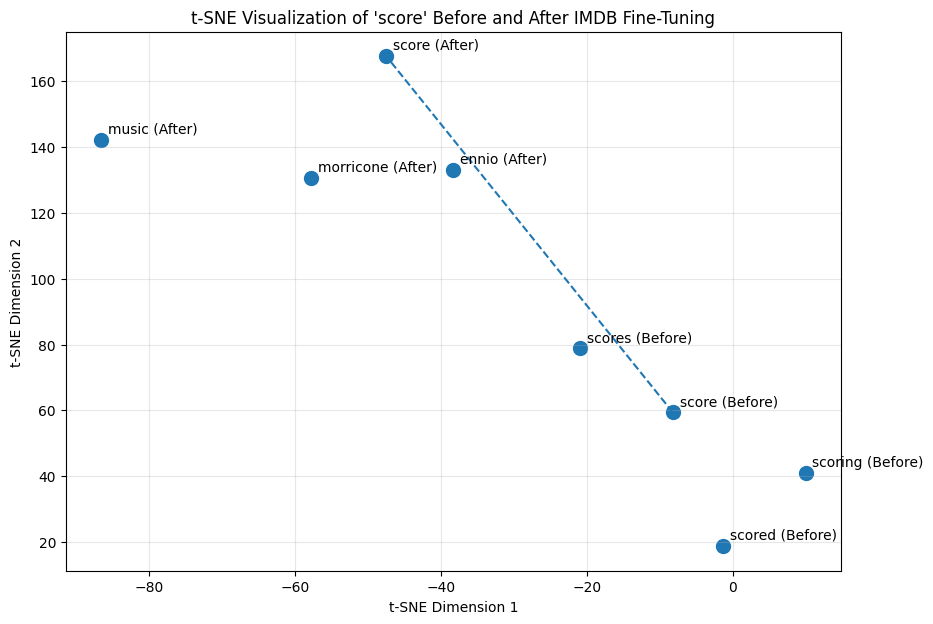

In [ ]:
# Step 16: Visualize the embedding shift using t-SNE

# Create the t-SNE model.
# n_components=2 reduces the 300-dimensional vectors to 2 dimensions.
# perplexity=3 is appropriate because we only have 8 data points.
# random_state makes the visualization reproducible.
tsne = TSNE(
    n_components=2,
    perplexity=3,
    random_state=1980,
    init="pca",
    learning_rate="auto"
)

# Convert the 300-dimensional vectors into 2D coordinates.
tsne_2d = tsne.fit_transform(tsne_vectors)

# Create the plot.
plt.figure(figsize=(10, 7))

# Plot each word as a point.
plt.scatter(
    tsne_2d[:, 0],
    tsne_2d[:, 1],
    s=100
)

# Add the word labels next to their corresponding points.
for i, label in enumerate(tsne_labels):
    plt.annotate(
        label,
        (tsne_2d[i, 0], tsne_2d[i, 1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Draw a dashed line between the original and fine-tuned
# positions of the target word "score".
plt.plot(
    [tsne_2d[0, 0], tsne_2d[1, 0]],
    [tsne_2d[0, 1], tsne_2d[1, 1]],
    linestyle="--"
)

# Add title and axis labels.
plt.title("t-SNE Visualization of 'score' Before and After IMDB Fine-Tuning")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

# Add a grid to make the positions easier to compare.
plt.grid(alpha=0.3)

# Display the final visualization.
plt.show()

In [ ]:
# Step 17: Print the final summary of the embedding transfer-learning experiment

print("Question 1 - Final Summary")
print("--------------------------")

print(
    "The pretrained Google News Word2Vec embeddings were fine-tuned "
    "using the IMDB movie review training corpus."
)

print(
    "\nAfter fine-tuning, the nearest neighbors became more specific "
    "to the movie-review domain."
)

print(
    "\nFor example, the pretrained neighbors of 'score' were "
    "'scoring', 'scores', and 'scored'."
)

print(
    "After IMDB fine-tuning, its neighbors changed to "
    "'morricone', 'music', and 'ennio', reflecting the movie-music "
    "meaning of the word 'score'."
)

print(
    "\nAmong the five target words, 'score' shifted the most "
    "(cosine similarity = 0.4856)."
)

print(
    "'screen' shifted the least "
    "(cosine similarity = 0.6661)."
)

print(
    "\nThe t-SNE visualization provides a 2D view of the change "
    "in the embedding neighborhood of 'score' after fine-tuning."
)

Question 1 - Final Summary
--------------------------
The pretrained Google News Word2Vec embeddings were fine-tuned using the IMDB movie review training corpus.

After fine-tuning, the nearest neighbors became more specific to the movie-review domain.

For example, the pretrained neighbors of 'score' were 'scoring', 'scores', and 'scored'.
After IMDB fine-tuning, its neighbors changed to 'morricone', 'music', and 'ennio', reflecting the movie-music meaning of the word 'score'.

Among the five target words, 'score' shifted the most (cosine similarity = 0.4856).
'screen' shifted the least (cosine similarity = 0.6661).

The t-SNE visualization provides a 2D view of the change in the embedding neighborhood of 'score' after fine-tuning.
